# The Calculus 1 Extra - 04. Calculus 1 Extra Practice with Integrals - Vol 2


<img src="./pics/cover.png" width=300> 

In [1]:
import setuptools

print("setuptools version:", setuptools.__version__)  # Should be < 70.0.0

import vpython as vp
from astropy import units as u
from astropy import constants as const
import sympy as sp
import numpy as np
from IPython.display import display, Math
import matplotlib.pyplot as plt
import sys
from pathlib import Path

print("All imports succeeded!")

setuptools version: 69.5.1


<IPython.core.display.Javascript object>

All imports succeeded!


In [2]:
!python --version

Python 3.13.13


In [4]:
pwd

'c:\\Users\\crodr\\Tutoriales\\Math\\Math_Tutor_DVD_Review\\Calculus_1_Extra_Practice\\03. Calculus 1 Extra Practice with Integrals - Vol 1'

In [3]:
C, n = sp.symbols("C, n", positive=True)
V, A, r, t, x, y, z, theta = sp.symbols("V, A, r, t, x, y, z, theta", real=True)
f, g, h = sp.symbols("f, g, h", cls=sp.Function)

In [4]:
# Add root folder to sys.path
sys.path.append(str(Path("../..").resolve()))

# Import your helper function directly
from helper_functions import fmt_vec, setup_math_axes


## Video 03. Calculating Volume with Integrals Using Cross-Sections


<img src="./pics/Fig03_01.png" width=400> 

<img src="./pics/Fig03_02.png" width=400> 

### Exercise 1
Volume using cross section (semicircle radius $x^2$):

<img src="./pics/Fig03_03.png" width=600> 

In [ ]:
# Cross-section A = 1/2 pi r^2 ==> A = 1/2 pi (x^2)^2
A = sp.Rational(1, 2) * sp.pi * x**4

V = sp.Integral(A, (x, 0, 1))
answer = V.doit()
display(Math(rf"{sp.latex(V)} = {sp.latex(answer)}"))

<IPython.core.display.Math object>

Exact volume: pi/10 ≈ 0.314159


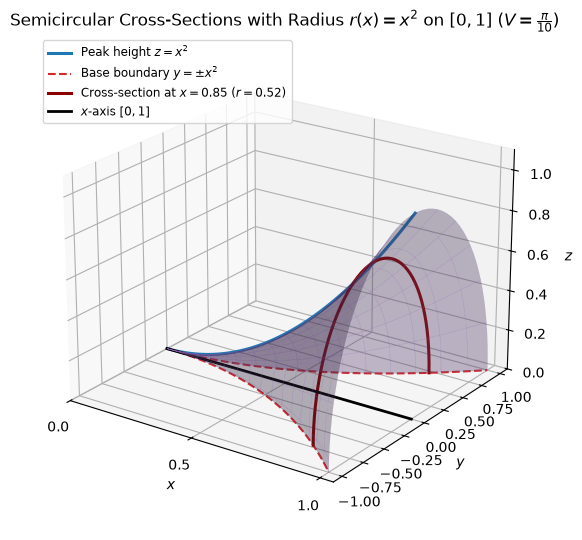

In [ ]:
# Symbolic radius r(x) = x^2 on [0, 1]
x = sp.Symbol("x", real=True, nonnegative=True)
r_sym = x**2
r_num = sp.lambdify(x, r_sym, "numpy")

# Volume check: V = \int_0^1 \frac{1}{2}\pi (r(x))^2 dx
V_exact = sp.integrate(sp.Rational(1, 2) * sp.pi * r_sym**2, (x, 0, 1))
print(f"Exact volume: {V_exact} ≈ {float(V_exact):.6f}")

# Grid for 3D semicircular slices: x in [0, 1], theta in [0, pi]
x_vals = np.linspace(0.0, 1.0, 60)
theta_vals = np.linspace(0.0, np.pi, 50)
X, THETA = np.meshgrid(x_vals, theta_vals)

R = r_num(X)
# Semicircle in the y-z plane perpendicular to the x-axis:
# y = r(x)*cos(theta) spans [-r(x), r(x)], z = r(x)*sin(theta) >= 0
Y = R * np.cos(THETA)
Z = R * np.sin(THETA)

fig = plt.figure(figsize=(8.5, 5.5))
ax = fig.add_subplot(111, projection="3d")

# Plot the 3D solid surface of semicircular cross-sections
ax.plot_surface(
    X,
    Y,
    Z,
    color="tab:purple",
    alpha=0.35,
    edgecolor="tab:purple",
    linewidth=0.2,
    rstride=4,
    cstride=4,
)

# Highlight top ridge (theta = pi/2, z = r(x)) and base edges (theta = 0, pi)
ax.plot(
    x_vals,
    np.zeros_like(x_vals),
    r_num(x_vals),
    color="tab:blue",
    linewidth=2.2,
    label=r"Peak height $z = x^2$",
)
ax.plot(
    x_vals,
    r_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:red",
    linewidth=1.5,
    linestyle="--",
    label=r"Base boundary $y = \pm x^2$",
)
ax.plot(
    x_vals,
    -r_num(x_vals),
    np.zeros_like(x_vals),
    color="tab:red",
    linewidth=1.5,
    linestyle="--",
)

# Highlight one representative semicircular cross-section at x = 0.85
x_slice = 0.85
r_slice = float(r_num(x_slice))
ax.plot(
    np.full_like(theta_vals, x_slice),
    r_slice * np.cos(theta_vals),
    r_slice * np.sin(theta_vals),
    color="darkred",
    linewidth=2.2,
    label=rf"Cross-section at $x = {x_slice}$ ($r = {r_slice**2:.2f}$)",
)

# x-axis reference line from 0 to 1
ax.plot([0, 1], [0, 0], [0, 0], color="black", linewidth=2, label=r"$x$-axis $[0, 1]$")

ax.set_xlim(0, 1.05)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(0, 1.1)
ax.set_xticks([0, 0.5, 1.0])
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(
    r"Semicircular Cross-Sections with Radius $r(x) = x^2$ on $[0, 1]$"
    rf" ($V = \frac{{\pi}}{{10}}$)"
)
ax.view_init(elev=22, azim=-55)
ax.legend(loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.show()